# Demanda y temperatura - EDELAP

Dos series cruzadas:

- **Demanda**: API de CAMMESA, region EDELAP (`id_region` 1943), una muestra cada
  **5 minutos** entre el 1/2/2026 y el 1/5/2026.
- **Temperatura del aire**: NSRDB (NREL), resolucion **horaria**. En el archivo
  cruzado se repite en las 12 muestras de cada hora.

La temperatura del NSRDB no la mide un satelite: se toma del reanalisis MERRA-2,
o sea que es un dato modelado y no la medicion de una estacion local. Por eso la
serie no tiene un solo hueco en 90 dias.

Objetivo: obtener la relacion entre temperatura y demanda para alimentar el modelo de NetLogo.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Unicas decisiones del analisis. Ningun corte en MW esta escrito a mano:
# los umbrales se calculan de la serie en las celdas que siguen.
F_RIC   = 3    # factor del rango intercuartil para atipicos extremos
VENTANA = 13   # muestras de la mediana movil
Z_MAX   = 4    # sigmas dentro de la misma hora del dia

pd.set_option('display.width', 120)

| Decision | Valor | De donde sale |
|---|---|---|
| Factor del RIC | 3 | criterio de atipico **extremo** (1,5 seria *leve*) |
| Ventana | 13 muestras | la temperatura es horaria, o sea 12 muestras, mas una para que sea impar y la mediana caiga sobre un dato real |
| Umbral de $z$ | 4 | menos de 2 falsas alarmas esperadas en 25.920 muestras |

El umbral del salto contra la mediana movil no figura aca porque tampoco se elige: se
mide del hueco de la cola, en el paso 4.


## 1. Carga

El CSV viene con BOM, de ahi el `utf-8-sig`.


In [2]:
df = pd.read_csv('data/demanda_la_plata_2026_con_temperatura.csv', encoding='utf-8-sig')
df.columns = [c.strip() for c in df.columns]
df['fecha'] = pd.to_datetime(df['fecha'], format='ISO8601')
df = df.sort_values('fecha').reset_index(drop=True)

df.head()

,fecha,dem_mw,id_region,temperatura_c
0,2026-02-01 00:05:00-03:00,364,1943,21.9
1,2026-02-01 00:10:00-03:00,359,1943,21.9
2,2026-02-01 00:15:00-03:00,357,1943,21.9
3,2026-02-01 00:20:00-03:00,357,1943,21.9
4,2026-02-01 00:25:00-03:00,353,1943,21.9


## 2. Exploracion inicial


In [3]:
print(df.shape)
print('nulos:', df.isna().sum().sum())
print('fechas duplicadas:', df.fecha.duplicated().sum())
print('rango:', df.fecha.min(), '->', df.fecha.max())
print('paso (min):', df.fecha.diff().dt.total_seconds().div(60).value_counts().to_dict())

df[['dem_mw', 'temperatura_c']].describe().round(2)

(25920, 4)
nulos: 0
fechas duplicadas: 0
rango: 2026-02-01 00:05:00-03:00 -> 2026-05-02 00:00:00-03:00
paso (min): {5.0: 25919}


,dem_mw,temperatura_c
count,25920.00,25920.00
mean,356.32,21.25
std,107.33,5.56
min,-1456.00,7.30
25%,306.00,17.40
50%,352.00,20.90
75%,397.00,25.00
max,1547.00,37.80


El minimo de `dem_mw` es **-1456 MW** y el maximo **1547**, contra una mediana de 352.


## 3. Tipificacion de la serie cruda

Tipificar es medir cada valor en desvios respecto del resto. Tres formas, que dan
resultados distintos:

$$z_i = \frac{x_i - \bar{x}}{s}
\qquad
z^{\text{rob}}_i = 0{,}6745\,\frac{x_i - \tilde{x}}{\text{MAD}}
\qquad \text{MAD} = \operatorname{mediana}\bigl|x_j - \tilde{x}\bigr|$$

$$\text{Tukey:}\quad x_i < Q_1 - 3\,\text{IQR} \;\lor\; x_i > Q_3 + 3\,\text{IQR}$$

El 0,6745 esta para que las dos escalas sean comparables: en una normal la MAD vale
0,6745 $\sigma$, asi que dividir por MAD y multiplicar por esa constante devuelve el z a
unidades de sigma.

El z clasico tiene un problema de fondo: los propios valores imposibles inflan $s$ y
terminan tapandose a si mismos. La mediana y la MAD no se dejan arrastrar.


In [4]:
x = df.dem_mw
mu, sd = x.mean(), x.std()
med, mad = x.median(), (x - x.median()).abs().median()
q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1

print(f'media {mu:.1f}  desvio {sd:.1f}   |   mediana {med:.1f}  MAD {mad:.1f}')

z  = (x - mu) / sd
zr = 0.6745 * (x - med) / mad
print(f'z clasico |z|>3 : {(z.abs()>3).sum():4d}')
print(f'z robusto |z|>3.5: {(zr.abs()>3.5).sum():4d}')
print(f'Tukey 3 IQR [{q1-3*iqr:.0f}, {q3+3*iqr:.0f}] : {((x<q1-3*iqr)|(x>q3+3*iqr)).sum():4d}')

media 356.3  desvio 107.3   |   mediana 352.0  MAD 45.0
z clasico |z|>3 :  180
z robusto |z|>3.5:  247
Tukey 3 IQR [33, 670] :  180


In [5]:
pd.DataFrame({'dem_mw': [x.min(), -198, 0, 214, 625, 756, 1068, x.max()]}).assign(
    z_clasico=lambda t: ((t.dem_mw - mu) / sd).round(2),
    z_robusto=lambda t: (0.6745 * (t.dem_mw - med) / mad).round(2))

,dem_mw,z_clasico,z_robusto
0,-1456,-16.89,-27.10
1,-198,-5.16,-8.24
2,0,-3.32,-5.28
3,214,-1.33,-2.07
4,625,2.50,4.09
5,756,3.72,6.06
6,1068,6.63,10.73
7,1547,11.09,17.91


El desvio crudo es **107 MW**; sacando los imposibles baja a **65**. Por eso el z clasico
subestima: el -1456 da -16.9 sigmas con el clasico y **-27.1** con el robusto.


## 4. Deteccion de anomalias

Dos criterios. Ninguno borra nada todavia: solo marcan.

**a) Atipicos extremos.** El criterio de caja y bigotes, sin inventar ningun limite:

$$\text{RIC} = Q_3 - Q_1
\qquad R_i = \bigl(x_i < Q_1 - 3\,\text{RIC}\bigr) \;\lor\; \bigl(x_i > Q_3 + 3\,\text{RIC}\bigr)$$

Los cuartiles toleran hasta un 25 % de contaminacion y aca hay un 1,1 %, asi que se
calculan sobre la serie sucia sin que los imposibles los muevan.


In [6]:
q1, q3 = df.dem_mw.quantile([.25, .75])
RIC = q3 - q1
LIM_INF, LIM_SUP = q1 - F_RIC * RIC, q3 + F_RIC * RIC

df['fuera_rango'] = (df.dem_mw < LIM_INF) | (df.dem_mw > LIM_SUP)
leves = (df.dem_mw < q1 - 1.5*RIC) | (df.dem_mw > q3 + 1.5*RIC)

print(f'Q1 {q1:.0f}   Q3 {q3:.0f}   RIC {RIC:.0f}')
print(f'leves    (1.5 RIC): [{q1-1.5*RIC:.0f}, {q3+1.5*RIC:.0f}] -> {leves.sum()}')
print(f'extremos ({F_RIC} RIC)  : [{LIM_INF:.0f}, {LIM_SUP:.0f}] -> {df.fuera_rango.sum()}')

Q1 306   Q3 397   RIC 91
leves    (1.5 RIC): [170, 534] -> 482
extremos (3 RIC)  : [33, 670] -> 180


El limite superior queda en 670 MW y el maximo legitimo del periodo es 625, asi que el
criterio no corta ninguna ola de calor. El de atipicos *leves* cortaria en 534 y se
llevaria 224 muestras legitimas: por eso corresponde el extremo.


**b) Apartamiento de la mediana movil.** El rango no ve un valor imposible que caiga
entre los dos limites. Para eso se compara cada muestra con la mediana de una ventana
centrada de $w = 13$ ($k = 6$ a cada lado, o sea $\pm 30$ min):

$$\tilde{x}_i = \operatorname{mediana}\,\{\, x_j \;:\; i-k \le j \le i+k \,\}
\qquad S_i = \bigl|\, x_i - \tilde{x}_i \,\bigr| > \delta$$

Se usa la **mediana** y no la media porque la media se deja arrastrar por los mismos
valores que se quieren detectar: un pico de 1500 MW mueve la media de su ventana unos
115 MW y la mediana, nada. En los bordes se exige mayoria de la ventana, 7 de 13.

El umbral $\delta$ tampoco se elige: se ordenan los residuos de mayor a menor y se lo
pone en el **hueco mas grande** de la cola, en su media geometrica.


In [7]:
dentro = df.dem_mw.where(~df.fuera_rango)
movil = dentro.rolling(VENTANA, center=True, min_periods=VENTANA // 2 + 1).median()
resid = (dentro - movil).abs()

orden = resid.dropna().sort_values(ascending=False).values[:20]
hueco = orden[:-1] / np.maximum(orden[1:], 1e-9)
i = hueco.argmax()
DELTA = np.sqrt(orden[i] * orden[i + 1])

print('residuos mas grandes:', orden[:6].round(0))
print(f'hueco mayor: {orden[i]:.0f} -> {orden[i+1]:.0f}   (x{hueco[i]:.1f})')
print(f'DELTA = {DELTA:.0f} MW')

df['salto'] = resid > DELTA
df['anomalo'] = df.fuera_rango | df.salto
print(f'{df.fuera_rango.sum()} por rango + {(df.salto & ~df.fuera_rango).sum()} por salto')

residuos mas grandes: [295.  69.  66.  51.  46.  41.]
hueco mayor: 295 -> 69   (x4.3)
DELTA = 143 MW
180 por rango + 1 por salto


Una muestra queda marcada si cumple cualquiera de los dos: $A_i = R_i \;\lor\; S_i$.


In [8]:
idx = df.index[df.anomalo].to_numpy()
rachas = np.split(idx, np.where(np.diff(idx) != 1)[0] + 1) if len(idx) else []

for r in sorted(rachas, key=len, reverse=True)[:5]:
    print(f'{len(r):4d} muestras  {df.fecha[r[0]]:%d/%m %H:%M} -> {df.fecha[r[-1]]:%d/%m %H:%M}'
          f'   dem [{df.dem_mw[r].min()}, {df.dem_mw[r].max()}]')

 178 muestras  19/04 10:10 -> 20/04 00:55   dem [-1456, 1547]
   1 muestras  15/02 11:20 -> 15/02 11:20   dem [-198, -198]
   1 muestras  22/03 03:00 -> 22/03 03:00   dem [0, 0]
   1 muestras  21/04 08:15 -> 21/04 08:15   dem [611, 611]


Una falla de telemetria de unas 15 h el 19/04 y tres muestras sueltas.

**La ventana no es critica.** Repitiendo el calculo con ventanas de 5 a 37 muestras se
marcan siempre las mismas: hay una meseta ancha y 13 cae adentro. Lo que si molesta es
agrandarla de mas: con 145 muestras (12 h) la mediana se atrasa respecto del ciclo diario
y sesga 51 MW en el pico de las 20, contra 1,3 MW con 13.


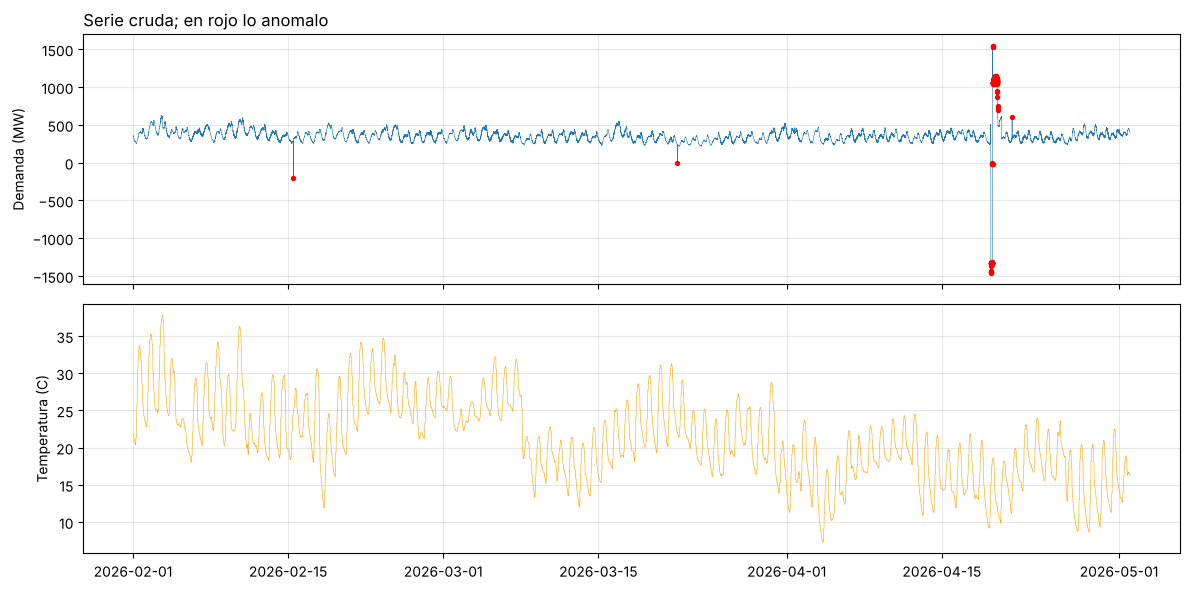

In [9]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(df.fecha, df.dem_mw, lw=.4)
ax[0].scatter(df.fecha[df.anomalo], df.dem_mw[df.anomalo], s=8, color='red', zorder=3)
ax[0].set_ylabel('Demanda (MW)'); ax[0].set_title('Serie cruda; en rojo lo anomalo', loc='left')
ax[1].plot(df.fecha, df.temperatura_c, lw=.4, color='orange')
ax[1].set_ylabel('Temperatura (C)')
for a in ax: a.grid(alpha=.3)
fig.tight_layout(); fig.savefig('figuras/00_serie_cruda.png', dpi=150)

## 5. Primera limpieza


In [10]:
limpio = df[~df.anomalo].drop(columns=['fuera_rango', 'salto', 'anomalo']).copy()
limpio['hora'] = limpio.fecha.dt.hour
limpio['dia'] = limpio.fecha.dt.date
limpio['finde'] = (limpio.fecha.dt.dayofweek >= 5).astype(int)

print(f'{len(limpio)} filas  ({100*len(limpio)/len(df):.2f} % del original)')
limpio[['dem_mw', 'temperatura_c']].describe().round(1)

25739 filas  (99.30 % del original)


,dem_mw,temperatura_c
count,25739.0,25739.0
mean,355.3,21.3
std,65.0,5.6
min,214.0,7.3
25%,306.0,17.4
50%,351.0,21.0
75%,396.0,25.0
max,640.0,37.8


## 6. Verificacion: tipificacion dentro de la hora

El z global no alcanza porque la demanda tiene un ciclo diario: 250 MW es normal a las 4
de la manana e imposible a las 20. Hay que tipificar **contra la misma hora del dia**,
o sea usar la media y el desvio del grupo al que la muestra pertenece:

$$z^{(h)}_i = \frac{x_i - \mu_{h(i)}}{\sigma_{h(i)}}
\qquad h(i) \in \{0, 1, \dots, 23\}$$

**Por que 4 sigmas.** Con $n = 25.626$ muestras, si la demanda de cada hora fuera normal
se esperarian por puro azar:

| Umbral | Probabilidad | Esperadas |
|---|---|---|
| $3\sigma$ | $2{,}7 \times 10^{-3}$ | 69 |
| $4\sigma$ | $6{,}3 \times 10^{-5}$ | **1,6** |
| $5\sigma$ | $5{,}7 \times 10^{-7}$ | 0,01 |

Con 3 sigmas habria 69 falsas alarmas y no se podria mirar ninguna. Con 4 se espera
menos de dos, asi que lo que aparezca ya no se explica por azar y vale la pena revisarlo
a mano. Con 5 el criterio se vuelve ciego.


In [11]:
g = limpio.groupby('hora').dem_mw
limpio['z_hora'] = (limpio.dem_mw - g.transform('mean')) / g.transform('std')

for k in (3, 4, 5):
    print(f'|z_hora| > {k}: {(limpio.z_hora.abs()>k).sum()}')

|z_hora| > 3: 261
|z_hora| > 4: 119
|z_hora| > 5: 71


In [12]:
(limpio[limpio.z_hora.abs() > Z_MAX]
 .groupby('dia')
 .agg(n=('dem_mw','size'), dem_min=('dem_mw','min'), dem_max=('dem_mw','max'),
      z_max=('z_hora','max'), temp_max=('temperatura_c','max'))
 .round(2))

,n,dem_min,dem_max,z_max,temp_max
dia,,,,,
2026-02-03,16,568,625,4.51,37.4
2026-04-20,103,480,640,7.12,13.8


Dos dias superan los 4 sigmas y **la temperatura los separa**:

| Dia | z max | T max | Veredicto |
|---|---|---|---|
| 03/02 | 4,5 | 37,4 C | ola de calor, el dia mas caluroso del periodo: **se conserva** |
| 20/04 | **7,1** | 13,8 C | 7,1 sigmas con 14 grados: **cola de la falla del 19** |

El filtro de la mediana movil no los agarro porque la mediana tambien estaba contaminada.


## 7. Segunda limpieza: la ventana de falla completa


In [13]:
FALLA = ('2026-04-19 09:45', '2026-04-20 10:00')

falla = limpio.fecha.between(*[pd.Timestamp(t, tz='-03:00') for t in FALLA])
print(f'descarta {falla.sum()} muestras mas')

limpio = limpio[~falla].copy()
g = limpio.groupby('hora').dem_mw
limpio['z_hora'] = (limpio.dem_mw - g.transform('mean')) / g.transform('std')
print(f'{len(limpio)} filas  ({100*len(limpio)/len(df):.2f} % del original)')
print(f'max |z_hora| ahora: {limpio.z_hora.abs().max():.2f}')

limpio[limpio.z_hora.abs() > Z_MAX].groupby('dia').agg(
    n=('dem_mw','size'), z_max=('z_hora','max'), temp_max=('temperatura_c','max')).round(2)

descarta 114 muestras mas
25625 filas  (98.86 % del original)
max |z_hora| ahora: 4.51


,n,z_max,temp_max
dia,,,
2026-02-03,16,4.51,37.4


Lo unico que queda arriba de 4 sigmas es el 03/02, que es real.


## 8. Revision del resto de las variables


In [14]:
t = limpio.temperatura_c
print(f'temperatura: media {t.mean():.1f}  desvio {t.std():.1f}  min {t.min()}  max {t.max()}')
print(f'|z| > 3: {(((t-t.mean())/t.std()).abs()>3).sum()}   max z: {((t.max()-t.mean())/t.std()):.2f}')

# rachas de valor repetido en la demanda: delatarian un sensor trabado
rachas_d = limpio.dem_mw.groupby((limpio.dem_mw != limpio.dem_mw.shift()).cumsum()).size()
print('racha mas larga de demanda repetida:', rachas_d.max())

temperatura: media 21.3  desvio 5.5  min 7.3  max 37.8
|z| > 3: 0   max z: 2.98
racha mas larga de demanda repetida: 8


La temperatura **no tiene outliers**: el maximo, 37,8 C, esta a 2,98 sigmas.

La demanda no tiene rachas largas de valor repetido, asi que no hay sensor trabado.


In [15]:
huecos = limpio.fecha.diff().dt.total_seconds().div(60)
print('huecos > 5 min:', (huecos > 5).sum(), ' el mayor:', f'{huecos.max():.0f} min')

n = limpio.groupby('dia').size()
n[n < 288]

huecos > 5 min: 4  el mayor: 1465 min


dia
2026-02-01    287
2026-02-15    287
2026-03-22    287
2026-04-19    117
2026-04-20    167
2026-04-21    287
2026-05-02      1
dtype: int64

Quedan huecos chicos donde se saco cada pinchazo, el de 24 h de la falla, y dos dias
incompletos en los bordes del periodo (01/02 y 02/05).


**La mediana movil es ciega a la temperatura.** Si la serie es constante en bloques de
$L = 12$ muestras, una ventana centrada de $w = 2k+1$ contiene al menos $k+1$ valores del
bloque propio y a lo sumo $k$ de los vecinos, asi que el bloque propio tiene **mayoria
estricta** y la mediana devuelve siempre el valor propio. El residuo da exactamente cero.
La condicion es $k \le L-1$, o sea $w \le 23$: con 13, y con cualquier ventana de hasta
dos horas, el filtro no puede detectar nada.

Por eso la temperatura se revisa a su granularidad real, un valor por hora, donde la
ventana de 5 h si abarca varios valores distintos.


In [16]:
hora_t = limpio.groupby(limpio.fecha.dt.floor('h')).temperatura_c.first()

q1t, q3t = hora_t.quantile([.25, .75])
rict = q3t - q1t
rt = (hora_t - hora_t.rolling(5, center=True, min_periods=3).median()).abs()
o = rt.dropna().sort_values(ascending=False).values[:10]
ght = hora_t.groupby(hora_t.index.hour)
zt = (hora_t - ght.transform('mean')) / ght.transform('std')

print(f'{len(hora_t)} valores horarios')
print(f'Tukey extremos       : [{q1t-3*rict:.1f}, {q3t+3*rict:.1f}] C -> '
      f'{((hora_t < q1t-3*rict) | (hora_t > q3t+3*rict)).sum()} marcados')
print(f'mediana movil de 5 h : apartamiento max {o[0]:.1f} C, hueco mayor x{o[0]/o[1]:.2f}')
print(f'z dentro de la hora  : max |z| = {zt.abs().max():.2f}')
print(f'salto entre horas    : max {hora_t.diff().abs().max():.1f} C')

2137 valores horarios
Tukey extremos       : [-5.0, 47.5] C -> 0 marcados
mediana movil de 5 h : apartamiento max 1.6 C, hueco mayor x1.23
z dentro de la hora  : max |z| = 2.55
salto entre horas    : max 4.4 C


Ningun criterio marca nada. El hueco de la cola es de x1,2 contra el x4,3 que tenia la
demanda: no hay nada que separar. El salto mayor entre horas, 4,4 C una tarde de febrero,
es un frente y no un error.

**La temperatura no tiene anomalias.** La ceguera de la mediana movil no tapo nada, pero
eso se sabe recien ahora.


**Cuantos dias distintos sostienen la rama caliente.** El total de muestras engana: la
temperatura es horaria y las horas calurosas se agrupan en pocos dias de verano.


In [17]:
cal = [28, 30, 32, 34, 35, 36, 37]
efectivo = pd.DataFrame(
    [(T, (limpio.temperatura_c >= T).sum(),
      limpio.fecha[limpio.temperatura_c >= T].dt.floor('h').nunique(),
      limpio.fecha[limpio.temperatura_c >= T].dt.date.nunique()) for T in cal],
    columns=['T_min', 'muestras', 'horas', 'dias']).set_index('T_min')
efectivo.T

T_min,28,30,32,34,35,36,37
muestras,3348,1728,840,336,204,96,60
horas,279,144,70,28,17,8,5
dias,34,20,12,6,3,2,1


El punto de 37 C son cinco horas de **un solo dia**, y los seis dias que aportan arriba
de 34 C son todos de febrero. Hay que declararlo: la pendiente del tramo caliente, que es
la que extrapola a los escenarios futuros, se apoya en seis dias, no en 25.625 muestras.


In [18]:
limpio.to_csv('data/demanda_limpio.csv', index=False)

## 9. Separar el efecto de la hora del de la temperatura

Las dos variables estan confundidas: las temperaturas bajas se miden de madrugada,
cuando la demanda es baja de todos modos, y las altas a la tarde, cuando es alta por el
ritmo de actividad. Un grafico directo de demanda contra temperatura mide el reloj.

La forma estandar de separarlos es estimar los dos efectos **a la vez**, con una
regresion que lleva una variable indicadora por cada combinacion de hora y tipo de dia
(48 en total) y dos tramos lineales para la temperatura. Asi no hay que elegir a mano
ninguna franja de referencia:

$$\log x_i = \underbrace{\alpha_{h(i),\,d(i)}}_{\text{1. Base horaria}}
+ \underbrace{a_1 \operatorname{clip}(T_i - b_1,\, 0,\, b_2 - b_1)}_{\text{2. Tramo tibio}}
+ \underbrace{a_2 \max(0,\, T_i - b_2)}_{\text{3. Tramo caliente}}
+ \underbrace{\varepsilon_i}_{\text{4. Error}}$$

Parte por parte:

1. **Base horaria.** Cuanto se consume normalmente a esa hora y ese tipo de dia. Son 48
   numeros, uno por combinacion, y los estima el propio ajuste.
2. **Tramo tibio.** Entre $b_1$ y $b_2$ la demanda sube $a_1$ por grado. El `clip` hace
   que valga 0 por debajo de $b_1$ y que deje de crecer en $b_2$.
3. **Tramo caliente.** Por encima de $b_2$ se suma $a_2$ por grado, que es la pendiente
   que de verdad importa. El `max` lo apaga por debajo de $b_2$.
4. **Error.** Lo que no explican ni la hora ni la temperatura: dia de la semana,
   actividad industrial, inercia termica.

Los cuatro quiebres y pendientes ($b_1$, $b_2$, $a_1$, $a_2$) salen del ajuste; mas
abajo dan 22 y 30,5 C.

Se trabaja sobre $\log x$ porque el efecto es multiplicativo: el calor sube la demanda
un porcentaje, no una cantidad fija de MW. Tomando logaritmo ese porcentaje pasa a ser
una suma y el ajuste vuelve a ser lineal.


In [19]:
g = (limpio.finde * 24 + limpio.hora).values   # 48 grupos: hora x tipo de dia
y = np.log(limpio.dem_mw.values)
T = limpio.temperatura_c.values
n, cnt = len(y), np.bincount(g)

def sin_grupo(v):
    """Resta la media del grupo. Permite ajustar solo la parte de temperatura."""
    v = np.atleast_2d(v.T).T
    return v - np.column_stack([(np.bincount(g, weights=v[:, j]) / cnt)[g]
                                for j in range(v.shape[1])])

def tramos(bs):
    b = list(bs) + [np.inf]
    return np.column_stack([np.clip(T - b[i], 0, b[i+1] - b[i]) for i in range(len(b) - 1)])

yd = sin_grupo(y).ravel()

def ajustar(bs):
    X = sin_grupo(tramos(bs))
    c, *_ = np.linalg.lstsq(X, yd, rcond=None)
    sc = ((yd - X @ c) ** 2).sum()
    return c, n * np.log(sc / n) + (48 + len(c)) * np.log(n)   # coeficientes, BIC

**Cuantos tramos.** Tampoco se decide mirando el grafico: se comparan por BIC, que
premia el ajuste y penaliza cada parametro de mas. Gana el BIC mas bajo.


In [20]:
from itertools import combinations
GRILLA = np.arange(12, 35, .5)

mejor = {}
for q in (1, 2, 3):
    b, bs = min((ajustar(c)[1], c) for c in combinations(GRILLA, q))
    mejor[q] = bs
    print(f'{q} quiebre(s) en {tuple(float(v) for v in bs)}:   BIC = {b:.0f}')

1 quiebre(s) en (24.0,):   BIC = -115184


2 quiebre(s) en (22.0, 30.5):   BIC = -115707


3 quiebre(s) en (13.0, 17.0, 30.0):   BIC = -115866


El BIC sigue bajando con tres quiebres, pero los dos que agrega caen en 13 y 17 grados:
es el efecto de **calefaccion**, que el proyecto declara fuera de alcance porque estudia
olas de calor y porque el periodo no cubre el invierno. Se queda con dos tramos, que es
el mejor modelo dentro de la rama de refrigeracion.


In [21]:
QUIEBRES = mejor[2]
A, _ = ajustar(QUIEBRES)
B1, B2 = (float(v) for v in QUIEBRES)

def k_de(t):
    return np.exp(A[0] * np.clip(t - B1, 0, B2 - B1) + A[1] * np.maximum(0, t - B2))

base = np.exp(pd.Series(y - tramos(QUIEBRES) @ A).groupby(g).mean())
perfil = pd.DataFrame({'habil': base.values[:24].round(0),
                       'finde': base.values[24:].round(0)})
perfil.index.name = 'hora'

print(f'quiebres   : {B1} C y {B2} C')
print(f'pendientes : +{100*(np.exp(A[0])-1):.2f} %/C  y  +{100*(np.exp(A[1])-1):.2f} %/C')
perfil.T

quiebres   : 22.0 C y 30.5 C
pendientes : +1.14 %/C  y  +4.43 %/C


hora,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
habil,343.0,317.0,299.0,291.0,287.0,289.0,303.0,310.0,327.0,345.0,...,367.0,364.0,363.0,367.0,377.0,407.0,434.0,431.0,405.0,376.0
finde,326.0,305.0,287.0,279.0,272.0,269.0,266.0,258.0,271.0,291.0,...,322.0,318.0,320.0,328.0,339.0,371.0,394.0,389.0,368.0,346.0


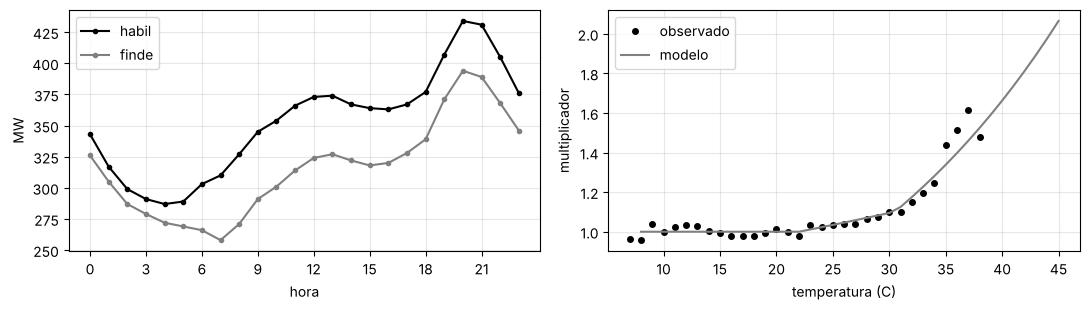

In [22]:
limpio['k_obs'] = limpio.dem_mw.values / base.values[g]
obs = limpio.groupby(limpio.temperatura_c.round()).k_obs.median()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(perfil.index, perfil.habil, marker='o', ms=3, color='black', label='habil')
ax[0].plot(perfil.index, perfil.finde, marker='o', ms=3, color='gray', label='finde')
ax[0].set_xlabel('hora'); ax[0].set_ylabel('MW'); ax[0].set_xticks(range(0, 24, 3))

t = np.arange(8, 46)
ax[1].plot(obs.index, obs.values, 'o', ms=4, color='black', label='observado')
ax[1].plot(t, k_de(t), color='gray', label='modelo')
ax[1].set_xlabel('temperatura (C)'); ax[1].set_ylabel('multiplicador')

for a in ax: a.grid(alpha=.3); a.legend()
fig.tight_layout(); fig.savefig('figuras/01_modelo.png', dpi=150)

## 10. Validacion

Cuanto explica el modelo sobre las mediciones sueltas, y cuanto de eso aporta la
temperatura por encima de la hora sola.


In [23]:
pred = base.values[g] * k_de(T)
d = limpio.dem_mw.values
sct = ((d - d.mean()) ** 2).sum()

print(f'R2 del modelo completo : {1 - ((d - pred)**2).sum() / sct:.3f}')
print(f'R2 solo con la hora    : {1 - ((d - base.values[g])**2).sum() / sct:.3f}')
print(f'error medio absoluto   : {np.abs(d - pred).mean():.1f} MW')

R2 del modelo completo : 0.650
R2 solo con la hora    : 0.510
error medio absoluto   : 28.6 MW


**Estabilidad de la pendiente caliente.** Si se apoya en seis dias, hay que ver si
alguno la sostiene solo. Se reajusta sacando cada uno.


In [24]:
dia = limpio.fecha.dt.date.values
calurosos = sorted(set(dia[limpio.temperatura_c.values >= 34]))

def pendientes(mask):
    gi = pd.factorize(g[mask])[0]
    c = np.bincount(gi)
    v = np.column_stack([np.clip(T[mask] - B1, 0, B2 - B1),
                         np.maximum(0, T[mask] - B2), y[mask]])
    v = v - np.column_stack([(np.bincount(gi, weights=v[:, j]) / c)[gi] for j in range(3)])
    co, *_ = np.linalg.lstsq(v[:, :2], v[:, 2], rcond=None)
    return 100 * (np.exp(co) - 1)

print('con todos : +%.2f  y  +%.2f %%/C' % tuple(pendientes(np.ones(len(y), bool))))
for d0 in calurosos:
    print(f'  sin {d0}: ' + '+%.2f  y  +%.2f %%/C' % tuple(pendientes(dia != d0)))

con todos : +1.14  y  +4.43 %/C
  sin 2026-02-02: +1.09  y  +4.26 %/C
  sin 2026-02-03: +1.04  y  +4.56 %/C
  sin 2026-02-08: +1.13  y  +4.46 %/C
  sin 2026-02-10: +1.07  y  +4.19 %/C
  sin 2026-02-21: +1.14  y  +4.60 %/C
  sin 2026-02-23: +1.13  y  +4.71 %/C


La pendiente caliente se mueve entre 4,2 y 4,7 %/C. Ningun dia la sostiene solo, asi que
el resultado aguanta, pero el numero honesto es ese rango y no un valor exacto.


La hora sola explica el 51 % y el modelo completo el 65 %: **la temperatura aporta 14
puntos**. El resto queda en manos del dia de la semana, la actividad industrial y la
inercia termica de los edificios, que el modelo no mira.

Es el numero que hay que declarar en la defensa. Para alimentar un modelo de agentes, que
trabaja con el comportamiento medio de 197 mil clientes y no con una medicion suelta,
alcanza; pero conviene decirlo antes de que lo pregunten.


## 11. Salida para el modelo

Tres archivos y una regla.


In [25]:
perfil.to_csv('data/perfil_base_horario.csv')

tabla = pd.DataFrame({'temperatura_c': np.arange(8, 46)})
tabla['k'] = k_de(tabla.temperatura_c.values).round(4)
tabla.to_csv('data/curva_temperatura.csv', index=False)

# reparto entre las 6 AT/MT de EDELAP, proporcional a clientes (shapefile del SIG)
CLIENTES = {'MT095': 73863, 'MT093': 55018, 'MT099': 38441,
            'MT092': 17488, 'MT194': 7390,  'MT195': 4772}
part = pd.DataFrame(CLIENTES.items(), columns=['sub', 'clientes'])
part['participacion'] = (part.clientes / part.clientes.sum()).round(4)
part.to_csv('data/participacion_subestaciones.csv', index=False)
part

,sub,clientes,participacion
0,MT095,73863,0.3750
1,MT093,55018,0.2793
2,MT099,38441,0.1952
3,MT092,17488,0.0888
4,MT194,7390,0.0375
5,MT195,4772,0.0242


La regla, lista para pegar en NetLogo:

```netlogo
to-report multiplicador-temp [ T ]
  let c1 max (list 0 (min (list (T - 22) 8.5)))   ; tramo 22 - 30.5 C
  let c2 max (list 0 (T - 30.5))                  ; tramo sobre 30.5 C
  report exp (0.01132 * c1 + 0.04338 * c2)
end

to-report demanda-sub [ hora finde? T participacion ]
  report (base-horaria hora finde?) * (multiplicador-temp T) * participacion * ESCALA
end
```


## 12. Conclusiones

**1. El dato crudo no se puede usar.** De 25.920 muestras hay que descartar 295. El
criterio de atipicos extremos saca 180, la mediana movil agrega una que caia dentro de
los limites, y la falla de telemetria del 19--20/04 aparecio recien al tipificar contra
la misma hora del dia, porque 24 h seguidas de basura contaminan su propia mediana movil.

**2. Ningun umbral se eligio a ojo.** El rango sale de los cuartiles, el salto sale del
hueco mas grande de la cola, la ventana sale de la resolucion horaria de la temperatura
y el corte de 4 sigmas sale de cuantas falsas alarmas se esperan en 25.920 muestras.

**3. La hora del dia pesa mas que la temperatura.** El perfil horario solo explica el
51 % de la varianza, y el modelo completo el 65 %.

**4. Hay un quiebre neto en 30,5 C.** Debajo de 22 C la demanda no reacciona. Entre 22 y
30,5 sube 1,14 % por grado. Arriba de 30,5 sube **4,43 % por grado**, casi cuatro veces
mas rapido. Ese salto es la firma de la simultaneidad de los aires acondicionados y es el
resultado principal: a 37 C la demanda es un 46 % mayor que la normal para esa hora.

**5. La temperatura es horaria.** Se repite en las 12 muestras de 5 minutos. Si el modelo
corre con paso de 5 minutos, la temperatura es la misma durante 12 ticks.

**6. Falta un factor de escala.** La demanda de CAMMESA es de toda la concesion de EDELAP
e incluye Berisso, Ensenada y Magdalena: llega a 625 MW de pico. Las 6 subestaciones AT/MT
que publica el SIG suman 403 MVA, unos 380 MW. El modelo no puede usar los 625 enteros;
hace falta decidir que fraccion de la region cubren esas 6, y esa decision queda abierta.

**7. Limites declarados.** El periodo va de febrero a mayo: no cubre el invierno y el
efecto de calefaccion, que el BIC detecta en 13 y 17 C, se deja afuera a proposito.
Arriba de 37 C no hay datos y la tabla extrapola con la pendiente del tramo caliente, que
se apoya en seis dias de febrero y vale entre 4,2 y 4,7 %/C segun cual se saque. La
demanda incluye comercio e industria, no solo residencial.
